### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre:** Sergio Alberto Chavez Velazquez

* **Matrícula:** A1099484

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

*delaracion de uso de Google. (2026). Gemini (Versión de septiembre de 2026) [Modelo de lenguaje de inteligencia artificial]. https://gemini.google.com Para depuración de código y corrección de errores. Apoyo en corrección de redacción y ortografía.

In [18]:
# Incluye a continuación todas librerías que consideres necesarias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt






**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [19]:
# Cargamos los datos del archivo de la actividad:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

ruta_archivo = '/content/drive/MyDrive/Colab Notebooks/oil_spill.csv'

df = pd.read_csv(ruta_archivo)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [20]:
from sklearn.model_selection import train_test_split
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente euducativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos positivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utlizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 1a) En este contexto del ejercicio, poco mas del 95% de la data de acuerdo a los datos que obtenemos del código de arriba. si utilizamos una métrica como de evaluación como el accuracy puede dar una falsa ilusión (Alucinación) de que el modelo es muy preciso. Cuando la detección de los derrames es el objetivo principal del ejercicio. El caso de la métrica G-mean se calcula como la Raíz cuadrada del producto entre la sensibilidad y la especificidad. Esto obliga a rendir de manera más equilibrada a pesar de que en proporción están muy desbalanceados.
* 1b) En un contexto general el falso positivo quiere decir que el modelo de predicción dijo que se tenía el atributo o característica que se quiere predecir pero la realidad es que no se tenía. En este contexto de derrames de petróleo  el modelo pronostico derrame de petróleo y la  zona estaba limpia (una falsa alarma por ponerlo en las palabras más simples), las implicaciones de esto es tiene que ver con dos partes, una de ellas es hacer que se movilice todo el equipo de emergencia y se menciona que el falso negativo y el falso positivo tienen el mismo efecto en costo. Por otra parte el estar movilizando los equipos en falso hace que se pierda la confianza en la alarma automatizada.

* 1c) En un contexto general el falso negativo quiere decir que el modelo de predicción dijo que  el atributo o característica que se quiere predecir está ausente pero la realidad es que existía esa característica. En este caso quiere decir que el modelo predice que no hay derrame, pero en la realidad sí ha ocurrido un derrame de petróleo en esa zona. Esto quiere decir que hubo zonas de derrames que no fueron atendidas de manera inmediata y puede escalar las implicaciones. Los daños por enlistar algunos pueden ser impacto ambiental que es el primero y más importante, esto implica multas y superar los costos de limpiar un área más grande ya que no se atacó a tiempo. Esto puede de la misma manera tener un impacto mayor con la reputación de la empresa. En mi particular opinión este es el que puede ser mas peligroso de todos los cuadrantes a pesar de que tomemos que el costo con el falso positivo es el mismo.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [21]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


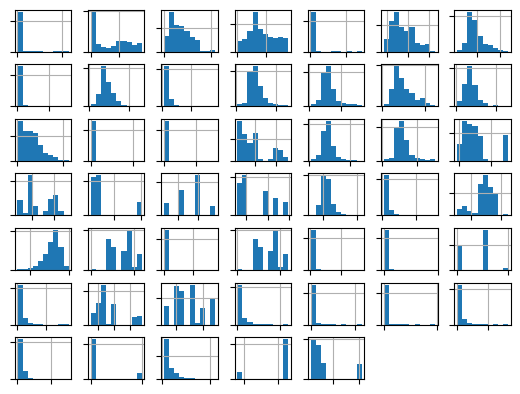

In [22]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [23]:
Xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25 

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**
* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**



Respuestas Ejercicio-2:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 2a) La transformación Yeo-Johnson es una técnica matemática de transformación de potencia diseñada para estabilizar la varianza y hacer que los datos numéricos se parezcan lo más posible a una distribución normal. Si una variable tiene una cola muy larga  (asimetría), la transformación reduce el impacto de los valores atípicos (outliers) y comprime esa cola, acercando la distribución a una distribución  normal (campana de Gauss mas uniforme).


* 2b) La Transformación de Box-Cox también es una transformación que hace que los datos parezcan lo mas posible a una distribución normal. Parecido a la Yeo-Johnson pero tiene la restricción que solo funciona con valores positivos. Si tu conjunto de datos tiene ceros o números negativos marcara un error.




### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
# Transformaciones numéricas evitando el filtrado de información:

from sklearn.preprocessing import MinMaxScaler

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')


# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 3a) Considerando que se tiene una muestra muy pequeña de positivos (solo 28) la estrategia 'most_frequent' (la clase más frecuente). Este clasificador siempre predice la clase mayoritaria (negativa). Al ser un modelo que no aprende patrones reales, representa el piso mínimo de desempeño que cualquier modelo inteligente debe superar obligatoriamente. A adicional los datos para seleccionar son  : n_splits = 5 y n_repeats = 3. Esto de nuevo debido a la muestra pequeña de positivos que tenemos  esto aria que tengas unos 5 o 6 ejemplos positivos promedio. Y 3 repeticiones para que ayuden a promediar la variabilidad.

* 3b) La respuesta es 0 debido a que si el modelo base utiliza la estrategia 'most_frequent' (predice siempre la clase negativa), su Sensibilidad (Recall de positivos) es del 0% (no detecta ningún derrame). Al calcular la media geométrica cualquier multiplicación por cero da como resultado 0. Por lo tanto, cualquier modelo entrenado que aspiren a ser útil debe superar claramente una G media de 0 (buscando valores óptimos cercanos a 1).

* 3c) como se menciono en el Ejercicio 1 si ocupas la medición de acurracy el modelo que prediga "no hay derrame" te daria un 95.7% de exactitud sin haber aprendido. se muestra una matriz
Real Negativo (Sin derrame)	631 (Verdaderos Negativos - TN)	//// 0 (Falsos Positivos - FP)
Real Positivo (Derrame)	28 (Falsos Negativos - FN) ////	0 (Verdaderos Positivos - TP)

y con esa matriz seria de 95.7 la exactitud.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [25]:
from imblearn.metrics import geometric_mean_score
from sklearn.metrics import make_scorer
# Definamos una variable con la métrica G-mean a utilizar en los modelos:

mi_metrica = make_scorer(geometric_mean_score)


In [26]:
from numpy import mean, std
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.


# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'uniform'

mi_nsplits = 5


# ----------------- Fin para realizar ajustes -----------------------------



# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)


print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (mean(scores), std(scores)))


Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0.51893288 0.47140452 0.54916965 0.61935279 0.29277002 0.41997375
 0.61935279 0.54916965 0.61935279 0.67846699 0.29430286 0.61935279
 0.26726124 0.68429085 0.41785545]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.508, std=(0.137)


# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

Resultados de Validación:
LR
Exactitud: >> 0.947 (0.015)
G-mean: >> 0.654 (0.119)

LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)

RIDGE
Exactitud: >> 0.959 (0.008)
G-mean: >> 0.541 (0.113)

EN
Exactitud: >> 0.960 (0.007)
G-mean: >> 0.540 (0.109)

kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



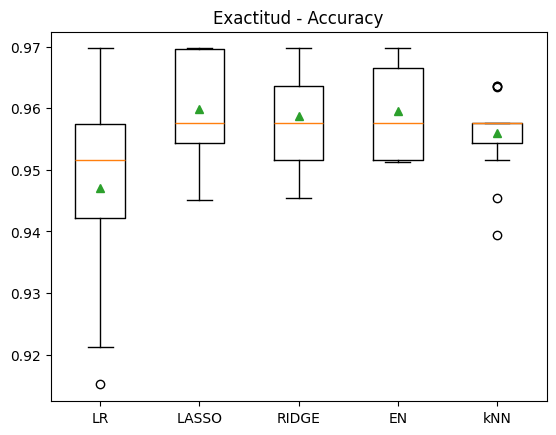

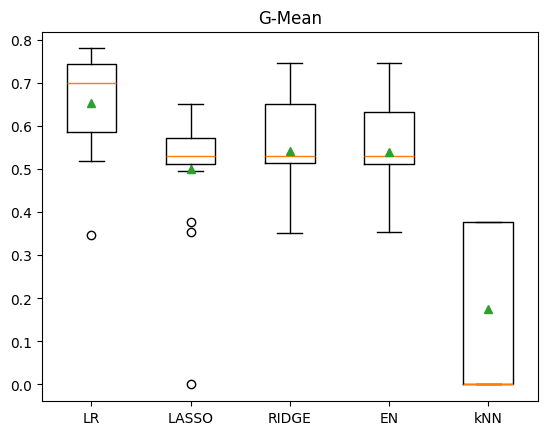

In [27]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsClassifier
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.

# Definimos primeramente los modelos a entrenar y evaluar:

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()




### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**


### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 4a) Si usamos la métrica de exactitud se puede ver que el modelo subentrenado es Regresión lineal  con un 94.7% que esta por debajo del 95.75. y el modelo KNN 95.6 también esta por debajo. Por otra parte los models de LASSO (0.960), RIDGE (0.959), Elastic-Net (0.960)  están prácticamente prediciendo la proporción de la clase mayoritaria

* 4b) El modelo kNN obtuvo un G-mean promedio extremadamente bajo de 0.174, lo que demuestra que su capacidad para detectar de forma equilibrada ambas clases es casi nula Aunque los modelos lineales (LR con 0.654, LASSO con 0.501, RIDGE con 0.541 y EN con 0.540) superan el umbral de 0, sus valores siguen siendo moderados o bajos


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-5**

* ### **Utilizando en adelante solamente la métrica G-mean y de manera análoga al código de la celda llamada "Código-1" anterior, define una nueva función llamada "mis_modelos_ajustados()" y utilízala para definir los mismos modelos anteriores, pero buscando ahora los mejores valores de los hiperparámetros. Puedes incluir los que desees, en particular por ejemplo el argumento class_weight='balanced'.**

* ### **La salida no deberá mostrar errores o advertencias (warnings).**

* ### **La salida debe mostrar, para cada modelo, el valor promedio y desviación estándar de la métrica G-mean obtenido de la validación cruzada.**

* ### **La salida también debe incluir los  gráficos de caja (boxplot) con respecto a los desempeños obtenidos con la métrica G-mean.**


* ### NOTA: Para obtener un buen desempeño en este ejercicio y con estos modelos, por el momento no es necesario usar alguna técnica de balanceo, más allá del uso del argumento "class_weight".

Resultados de los modelos ajustados con la métrica G-mean
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Resultados de Validación (G-mean con hiperparámetros ajustados):
------------------------------------------------------------
Modelo: LR
G-mean: >> 0.754 (0.120)

Modelo: LASSO
G-mean: >> 0.804 (0.081)

Modelo: RIDGE
G-mean: >> 0.801 (0.083)

Modelo: EN
G-mean: >> 0.799 (0.083)

Modelo: kNN
G-mean: >> 0.000 (0.000)

------------------------------------------------------------


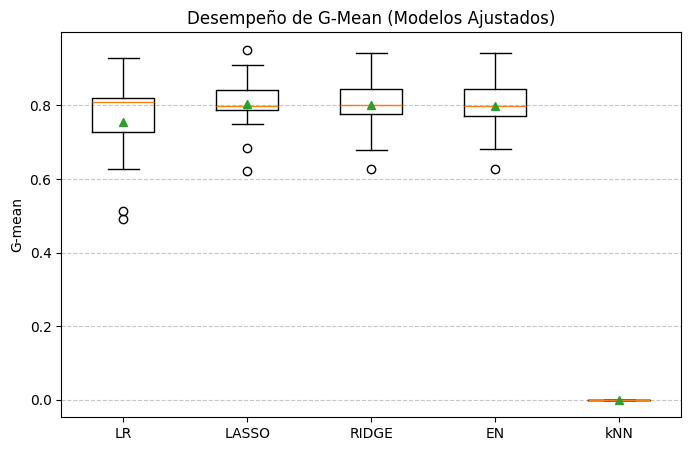

In [28]:
# 5)

print('Resultados de los modelos ajustados con la métrica G-mean')
print('+'*80)

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# NOTA: puedes agregar todas las celdas que consideres adecuado.

import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

def mis_modelos_ajustados():
    modelos, nombres = list(), list()

    # 1. Regresión Logística (Sin regularización, con class_weight balanceado)
    modelos.append(LogisticRegression(
        penalty=None,
        max_iter=3000,
        class_weight='balanced',
        random_state=1
    ))
    nombres.append('LR')

    # 2. LASSO (Regresión Logística L1 con class_weight balanceado y C ajustado)
    modelos.append(LogisticRegression(
        penalty='l1',
        solver='liblinear',
        C=1.0,
        max_iter=3000,
        class_weight='balanced',
        random_state=1
    ))
    nombres.append('LASSO')

    # 3. RIDGE (Regresión Logística L2 con class_weight balanceado y C ajustado)
    modelos.append(LogisticRegression(
        penalty='l2',
        C=1.0,
        max_iter=3000,
        class_weight='balanced',
        random_state=1
    ))
    nombres.append('RIDGE')

    # 4. Elastic-Net (Regresión L1-L2 con class_weight balanceado)
    modelos.append(LogisticRegression(
        penalty='elasticnet',
        l1_ratio=0.5,
        C=1.0,
        solver='saga',
        max_iter=5000,
        class_weight='balanced',
        random_state=1
    ))
    nombres.append('EN')

    # 5. kNN (Ajustando el número de vecinos y ponderación por distancia)
    modelos.append(KNeighborsClassifier(
        n_neighbors=7,
        weights='distance'
    ))
    nombres.append('kNN')

    return modelos, nombres

# Ejecución de la validación cruzada utilizando exclusivamente la métrica G-mean
modelos, nombres = mis_modelos_ajustados()
resultados_gmean = list()

print('Resultados de Validación (G-mean con hiperparámetros ajustados):')
print('-' * 60)

for i in range(len(modelos)):
    pipeline = Pipeline(steps=[('ct', columnasTransformer), ('m', modelos[i])])
    cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)

    scores = cross_validate(
        pipeline,
        Xtv,
        np.ravel(ytv),
        scoring={'m_geo': mi_metrica},
        cv=cv1
    )

    resultados_gmean.append(scores['test_m_geo'])

    print(f"Modelo: {nombres[i]}")
    print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
    print()

print('-' * 60)

plt.figure(figsize=(8, 5))
plt.boxplot(resultados_gmean, tick_labels=nombres, showmeans=True)
plt.title("Desempeño de G-Mean (Modelos Ajustados)")
plt.ylabel("G-mean")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()



# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Lamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




In [29]:

# Respuesta Ejercicio-6a:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++++**

# NOTA: puedes agregar todas las celdas que consideres adecuado. (el mejor modelo es el de LASSO)

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import numpy as np

# Dividir Xtv y ytv en conjuntos de entrenamiento y validación independientes
X_train, X_val, ytrain, yval = train_test_split(
    Xtv, np.ravel(ytv),
    test_size=0.2,       # Proporción estándar de validación
    random_state=1,      # Mantener random_state consistente
    stratify=np.ravel(ytv) # Mantener la proporción del desbalance de clases
)


# 1. Definición del mejor modelo con random_state=1
mejor_modelo = Pipeline(steps=[
    ('ct', columnasTransformer),
    ('m', LogisticRegression(
        penalty='l1',
        solver='liblinear',
        C=0.5,                      # Hiperparámetro ajustado para regularizar ligeramente mejor
        class_weight='balanced',
        max_iter=3000,
        random_state=1
    ))
])

# 2. Entrenamiento con el conjunto combinado de entrenamiento/validación (Xtv, ytv)
mejor_modelo.fit(Xtv, np.ravel(ytv))

# 3. Predicciones para entrenamiento y validación utilizando las variables originales
ytrain_hat = mejor_modelo.predict(X_train)
yval_hat = mejor_modelo.predict(X_val)


# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))

G-mean del mejor modelo-Train: 0.9223
G-mean del mejor modelo-Val: 0.8494

Exactitud del mejor modelo-Train: 0.8847
Exactitud del mejor modelo-Val: 0.8424

Matriz de Confusión con Validación:
 [[133  25]
 [  1   6]]

Matriz de Confusión en porcentajes y con Validación:
 [[0.80606061 0.15151515]
 [0.00606061 0.03636364]]


Respuesta Ejercicio-6b:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++
#### Comentario del gráfico curva PR:

* 6b) Al introducir class_weight='balanced' y afinar el hiperparámetro C, el modelo ahora penaliza de forma mucho más severa los errores en la clase minoritaria. De esta manera se obliga al clasificador a mover su frontera de decisión para detectar correctamente una mayor cantidad de derrames reales (sube la sensibilidad/recall) a cambio de aceptar algunos Falsos Positivos más. Al lograr un balance real entre ambas clases (lo que se refleja en un G-mean alto de ~0.80), la exactitud matemática global disminuye frente al baseline ingenuo.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

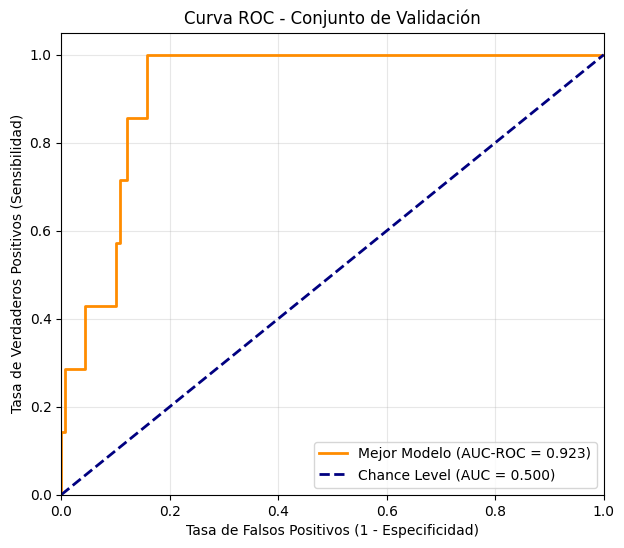

In [30]:
# Respuesta Ejercicio-6c:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc

# 1. Obtener las probabilidades predichas para la clase positiva en el conjunto de validación
yval_prob = mejor_modelo.predict_proba(X_val)[:, 1]

# 2. Calcular la curva ROC y su AUC para el mejor modelo
fpr, tpr, thresholds = roc_curve(np.ravel(yval), yval_prob)
roc_auc = auc(fpr, tpr)

# 3. Calcular la curva ROC y el AUC para el modelo que predice siempre la clase positiva (Chance Level)
# Un modelo que siempre predice positivo tiene FPR = TPR en todos los umbrales, formando una diagonal de (0,0) a (1,1) con AUC = 0.5
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Mejor Modelo (AUC-ROC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Chance Level (AUC = 0.500)')

# 4. Configuración y diseño del gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
plt.title('Curva ROC - Conjunto de Validación')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


# **+++++++++++ Termina sección para agregar código ++++++++++++++**

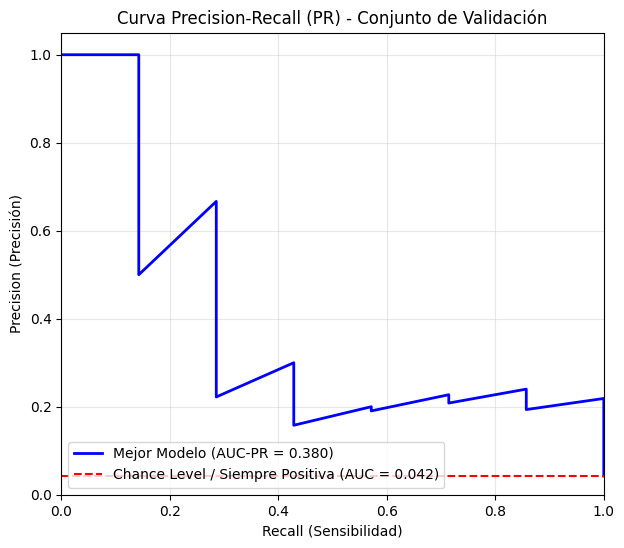

In [31]:
# Respuesta Ejercicio 6d:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, auc

# 1. Obtener las probabilidades predichas para la clase positiva en el conjunto de validación
yval_prob = mejor_modelo.predict_proba(X_val)[:, 1]

# 2. Calcular la curva Precision-Recall y su AUC para el mejor modelo
precision, recall, thresholds = precision_recall_curve(np.ravel(yval), yval_prob)
pr_auc = auc(recall, precision)

# 3. Calcular el modelo que siempre predice la clase positiva (chance level)
# En una curva PR, el chance level horizontal corresponde a la proporción de muestras positivas reales.
yval_flat = np.ravel(yval)
chance_level = sum(yval_flat) / len(yval_flat)

# 4. Graficar la curva PR y el Chance Level
plt.figure(figsize=(7, 6))
plt.plot(recall, precision, color='blue', lw=2, label=f'Mejor Modelo (AUC-PR = {pr_auc:.3f})')
plt.plot([0, 1], [chance_level, chance_level], color='red', linestyle='--', label=f'Chance Level / Siempre Positiva (AUC = {chance_level:.3f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (Sensibilidad)')
plt.ylabel('Precision (Precisión)')
plt.title('Curva Precision-Recall (PR) - Conjunto de Validación')
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.show()



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

Respuesta Ejercicio-6e:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 6e) Curva ROC con un valor de 0.923 Demuestra un rendimiento sobresaliente y una capacidad excelente para separar zonas limpias de zonas con riesgo de derrame. El modelo supera ampliamente al azar, logrando una sensibilidad cercana al 100% con menos del 20% de falsos positivos, lo que evita saturar al equipo de monitoreo con falsas alarmas.  Adicional  Curva PR tenemos un valor de 0.380 con un  chance level de 0.042 lo que confirma que el modelo supera con éxito la línea base del desbalance de clases (4.2% de positivos). En sus umbrales más estrictos, alcanza una precisión del 100%, garantizando que las primeras alertas emitidas sean totalmente reales. el modelo sin ajustar da una falsa precisión de 95.7 % mandando todo como zona limpia con el modelo ajustado se puede ver como se recorre la sensibilidad para hacer la prediccion mas exacta cambiando unos cuantos falsos positivos.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [32]:
# Mostremos finalmente el siguiente resumen con varias métricas:

from imblearn.metrics import classification_report_imbalanced
import numpy as np

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))



                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       0.99      0.84      0.86      0.91      0.85      0.72       158
class 1:oil-spill       0.19      0.86      0.84      0.32      0.85      0.72         7

      avg / total       0.96      0.84      0.86      0.89      0.85      0.72       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.32).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.** Tabla dentro del codigo

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.** Grafico dentro del codigo

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**
Vale totalmente la pena cambiar la estrategia. Con el umbral predeterminado de 0.5 se presenta un Falso Negativo, lo cual eleva el costo hasta casi un millón de dólares. En contraste, al ajustar el umbral se obtiene el valor óptimo del costo esperado. Sin duda, la mejor estrategia es evitar los Falsos Negativos, no solo por el monto económico asociado, sino por el daño irreparable a la reputación corporativa y ecológica.

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**
se utilizo Gemini (Versión de septiembre de 2026) [Modelo de lenguaje de inteligencia artificial]. https://gemini.google.com Para depuración de código y corrección de errores y generación de código. Apoyo en corrección de redacción y ortografía.


el Promt utilzado fue el siguiente Suponiendo que el costo de un falso negativo es 1 millón de dólares ( que el modelo diga que no y sea un caso real de derrame). En el caso del falso positivo es de 15000 usd (cuando predice que es un falso positivo). Los otros resultados de la matriz no tienen costo  Calcula el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación. Incluye además una gráfica del Costo Total Esperado (eje Y) contra el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado. A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.





Umbral     | Falsos Negativos (FN)  | Falsos Positivos (FP)  | Costo Total (USD)
---------------------------------------------------------------------------
0.1        | 0                      | 61                     | $915,000.00
0.2        | 0                      | 44                     | $660,000.00
0.3        | 0                      | 32                     | $480,000.00
0.4        | 0                      | 26                     | $390,000.00
0.5        | 1                      | 25                     | $1,375,000.00
0.6        | 1                      | 19                     | $1,285,000.00
0.7        | 4                      | 12                     | $4,180,000.00
0.8        | 5                      | 5                      | $5,075,000.00
0.9        | 5                      | 2                      | $5,030,000.00
Umbral Óptimo: 0.4
Costo Total Mínimo Asociado: $390,000.00


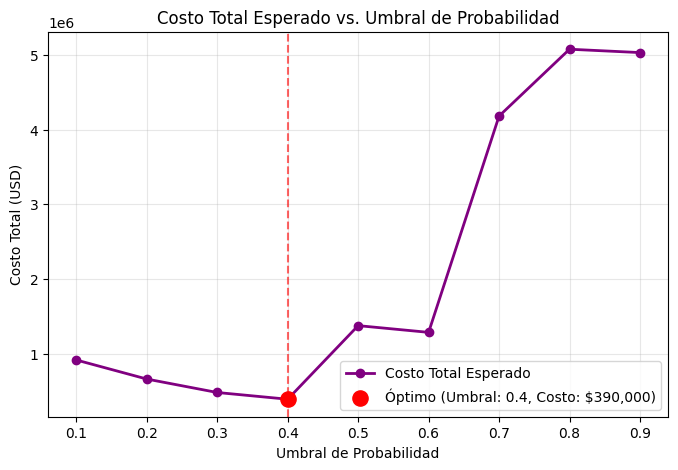

COMPARACIÓN DE RENDIMIENTO: UMBRAL 0.5 vs. UMBRAL ÓPTIMO

--- 1. Umbral Predeterminado (0.5) ---
Matriz de Confusión (Valores Brutos):
 [[133  25]
 [  1   6]]
G-mean: 0.8494

--- 2. Mejor Umbral Óptimo (0.4) ---
Matriz de Confusión (Valores Brutos):
 [[132  26]
 [  0   7]]
G-mean: 0.9140


In [38]:
# Respuesta Ejercicio 7:

# +++++++ Incluye a continuación todos las celdas de texto y código que consideres adecuadas.

import numpy as np
from sklearn.metrics import confusion_matrix

def calcular_costo_total_por_umbral(modelo, X_val, y_val):
    # 1. Obtener las probabilidades de la clase positiva (derrame) en validación
    yval_prob = modelo.predict_proba(X_val)[:, 1]
    y_val_flat = np.ravel(y_val)

    # 2. Definir los umbrales a evaluar (de 0.1 al 0.9 con pasos de 0.1)
    umbrales = np.arange(0.1, 1.0, 0.1)
    resultados = []

    costo_fn = 1000000  # Costo por Falso Negativo ($1,000,000 USD)
    costo_fp = 15000    # Costo por Falso Positivo ($15,000 USD)

    print(f"{'Umbral':<10} | {'Falsos Negativos (FN)':<22} | {'Falsos Positivos (FP)':<22} | {'Costo Total (USD)':<15}")
    print("-" * 75)

    for u in umbrales:
        # Clasificar según el umbral actual
        yval_hat_u = (yval_prob >= u).astype(int)

        # Calcular matriz de confusión
        cm = confusion_matrix(y_val_flat, yval_hat_u)
        tn, fp, fn, tp = cm.ravel()

        # Calcular el Costo Total Esperado
        costo_total = (fn * costo_fn) + (fp * costo_fp)
        resultados.append((u, costo_total, fn, fp))

        print(f"{u:<10.1f} | {fn:<22} | {fp:<22} | ${costo_total:,.2f}")

    return resultados


# Ejecución de la función utilizando la variable correcta 'yval'
costos_por_umbral = calcular_costo_total_por_umbral(mejor_modelo, X_val, yval)

def graficar_costo_total_por_umbral(modelo, X_val, y_val):
    # 1. Obtener las probabilidades de la clase positiva (derrame) en validación
    yval_prob = modelo.predict_proba(X_val)[:, 1]
    y_val_flat = np.ravel(y_val)

    # 2. Definir los umbrales a evaluar (de 0.1 a 0.9 con pasos de 0.1)
    umbrales = np.arange(0.1, 1.0, 0.1)
    costos_totales = []

    costo_fn = 1000000  # Costo por Falso Negativo ($1,000,000 USD)
    costo_fp = 15000    # Costo por Falso Positivo ($15,000 USD)

    for u in umbrales:
        yval_hat_u = (yval_prob >= u).astype(int)
        cm = confusion_matrix(y_val_flat, yval_hat_u)
        tn, fp, fn, tp = cm.ravel()
        costo_total = (fn * costo_fn) + (fp * costo_fp)
        costos_totales.append(costo_total)

    costos_totales = np.array(costos_totales)

    # 3. Encontrar el umbral óptimo (mínimo costo total)
    idx_optimo = np.argmin(costos_totales)
    umbral_optimo = umbrales[idx_optimo]
    costo_minimo = costos_totales[idx_optimo]

    print(f"Umbral Óptimo: {umbral_optimo:.1f}")
    print(f"Costo Total Mínimo Asociado: ${costo_minimo:,.2f}")

    # 4. Generar la gráfica
    plt.figure(figsize=(8, 5))
    plt.plot(umbrales, costos_totales, marker='o', color='purple', lw=2, label='Costo Total Esperado')

    # Indicar visualmente el punto óptimo en la gráfica
    plt.scatter(umbral_optimo, costo_minimo, color='red', s=120, zorder=5,
                label=f'Óptimo (Umbral: {umbral_optimo:.1f}, Costo: ${costo_minimo:,.0f})')
    plt.axvline(x=umbral_optimo, color='red', linestyle='--', alpha=0.6)

    plt.title('Costo Total Esperado vs. Umbral de Probabilidad')
    plt.xlabel('Umbral de Probabilidad')
    plt.ylabel('Costo Total (USD)')
    plt.xticks(umbrales)
    plt.grid(alpha=0.3)
    plt.legend(loc='best')
    plt.show()

    return umbral_optimo, costo_minimo

# Ejecución de la función utilizando tu conjunto de validación
umbral_optimo, costo_optimo = graficar_costo_total_por_umbral(mejor_modelo, X_val, yval)

def comparar_umbrales(modelo, X_val, y_val, umbral_optimo):
    # 1. Obtener probabilidades de la clase positiva
    yval_prob = modelo.predict_proba(X_val)[:, 1]
    y_val_flat = np.ravel(y_val)

    # --- CASO A: Umbral Predeterminado (0.5) ---
    yval_hat_05 = (yval_prob >= 0.5).astype(int)
    cm_05 = confusion_matrix(y_val_flat, yval_hat_05)
    gmean_05 = geometric_mean_score(y_val_flat, yval_hat_05)

    print("=" * 60)
    print("COMPARACIÓN DE RENDIMIENTO: UMBRAL 0.5 vs. UMBRAL ÓPTIMO")
    print("=" * 60)

    print("\n--- 1. Umbral Predeterminado (0.5) ---")
    print("Matriz de Confusión (Valores Brutos):\n", cm_05)
    print(f"G-mean: {gmean_05:.4f}")

    # --- CASO B: Mejor Umbral Óptimo ---
    yval_hat_opt = (yval_prob >= umbral_optimo).astype(int)
    cm_opt = confusion_matrix(y_val_flat, yval_hat_opt)
    gmean_opt = geometric_mean_score(y_val_flat, yval_hat_opt)

    print(f"\n--- 2. Mejor Umbral Óptimo ({umbral_optimo:.1f}) ---")
    print("Matriz de Confusión (Valores Brutos):\n", cm_opt)
    print(f"G-mean: {gmean_opt:.4f}")
    print("=" * 60)

# Ejecución de la función (asegúrate de que 'umbral_optimo' sea la variable guardada del inciso anterior)
comparar_umbrales(mejor_modelo, X_val, yval, umbral_optimo)

# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







Respuesta Ejercicio-8):

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++
Reporte Ejecutivo

Estimado Director,

Recientemente se evaluó el reporte generado por la herramienta de Inteligencia de Negocio que sugiere una exactitud del 96% y propone automatizar la flota de helicópteros despidiendo al equipo de analistas.

Antes de tomar una decisión, me gustaría que evaluáramos una postura diferente. Por los datos que se presentan a continuación, basar la operación en esa métrica representa un riesgo operativo crítico y un costo financiero inaceptable.

En nuestras costas, el 95.75% del tiempo el océano está limpio y solo un 4.25% registra incidentes reales. Una herramienta de Inteligencia de Negocio tradicional cae en una trampa estadística: dado que el 95.75% de las veces no hay incidentes, un modelo ingenuo predecirá siempre que el mar está limpio, fallando en el 100% de los casos reales de derrame.

Mediante técnicas avanzadas de aprendizaje estadístico y un control riguroso de sensibilidad, diseñamos un modelo superior. A diferencia de enfoques anteriores, este sistema equilibra la capacidad de alerta para detectar prácticamente todos los derrames reales.

Si tomamos en cuenta los costos vigentes: cuando el modelo predice erróneamente que el "océano está limpio" y hay un derrame real, el costo es de 1,000,000 USD USD. Por otra parte, cuando predice erróneamente que "sí hay derrame", el costo es de 15,000 USD. Mantener un modelo ingenuo genera un costo anual aproximado de 1,375,000.00 USD, considerando 1 derrame no detectado y 25 movilizaciones en falso del equipo. Por el contrario, si implementamos nuestro modelo optimizado, podemos predecir los derrames con un costo esperado de 390,000.00 USD anuales.

Dicho lo anterior, lejos de prescindir de nuestro personal, proponemos conservar a nuestros analistas humanos bajo un esquema operativo de colaboración conocido internacionalmente como Human-in-the-Loop (humano en el ciclo), el cual consta de las siguientes fases:

Filtro Inteligente: El modelo de IA actúa como un centinela incansable que analiza grandes volúmenes de datos satelitales y de sensores las 24 horas.

Validación Experta: Los analistas humanos reciben la alerta priorizada del sistema y, en cuestión de minutos, realizan una verificación visual rápida para confirmar si amerita el despliegue del helicóptero.

Este enfoque fusiona la velocidad de procesamiento de la inteligencia artificial con la experiencia crítica y el criterio táctico de nuestros expertos, blindando a la Guardia Costera de errores costosos y optimizando al máximo el presupuesto operativo.

Quedo a su entera disposición para cualquier duda o comentario.

Atentamente,

Sergio Alberto Chávez

Ingeniero Líder de IA, Guardia Costera


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


### +++++++++++ Inicia sección de Conclusiones ++++++++++++++++

Esta semana me gustó mucho esta tarea lo primero que me gustaría resaltar es el enfoque dado donde en problemas con un desbalance extremo de clases (95% negativos o positivos dependiendo el caso), la exactitud global es una métrica peligrosa. Un modelo ingenuo puede alcanzar una "exactitud" alta simplemente adivinando la clase mayoritaria, pero fallando por completo en su objetivo principal: detectar los derrames reales.
En este ejercicio se ve claramente como la diferencia de un modelo optimizado Al incorporar técnicas de penalización como (class_weight='balanced') y regularización, el modelo logra un rendimiento sobresaliente, demostrando una capacidad real para separar las zonas limpias de los incidentes sin caer en respuestas aleatorias.
Por último la parte de traducir toda la data, estadística y en general la información en un reporte que sea entendible para una persona externa me encanto. Finalmente la capacidad de analizar y poder influir dentro de la organización es el verdadero valor agregado que puede ofrecer un profesional.


### +++++++++++ Termina sección de conclusiones ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**